# UCF101 — Regularized BiLSTM + Temporal Attention Experiment

This experiment tests whether a smaller, more strongly regularized model generalizes better than the previous BiLSTM + attention run.

Previous baseline: test accuracy 68.55%, balanced accuracy 60.80%, macro-F1 60.96%, best validation macro-F1 0.6210.

New settings: hidden size 64, one LSTM layer, dropout 0.50, weight decay 0.005, learning rate 0.0003, label smoothing 0.10, patience 8.

Uses existing sequences only; does not re-extract poses. Output filenames are new, so the previous model and reports remain unchanged.


In [1]:
from pathlib import Path
import copy, gc, json, logging, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQUENCE_DIR = PROJECT_DIR / "data" / "processed" / "sequences_all"
OUTPUT_MODEL_DIR = PROJECT_DIR / "outputs" / "models"
OUTPUT_REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
RECOVERY_DIR = OUTPUT_MODEL_DIR / "lstm_bilstm_attention_regularized_checkpoints"
for folder in (OUTPUT_MODEL_DIR, OUTPUT_REPORT_DIR, RECOVERY_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_DIR)
print("Sequence directory:", SEQUENCE_DIR)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
assert SEQUENCE_DIR.is_dir(), f"Sequence directory not found: {SEQUENCE_DIR}"


Project: C:\Users\admin\ViTPose_Action_Recognition
Sequence directory: C:\Users\admin\ViTPose_Action_Recognition\data\processed\sequences_all
PyTorch: 2.7.1+cu118
Device: cuda
GPU: NVIDIA RTX A4000


## 1. Load the existing split arrays

Expected filenames are shown below. If your current notebook uses different filenames, edit `required_files` to match. The arrays are memory-mapped to reduce RAM use.


In [2]:
required_files = {
    "X_train": SEQUENCE_DIR / "X_train.npy",
    "X_val": SEQUENCE_DIR / "X_val.npy",
    "X_test": SEQUENCE_DIR / "X_test.npy",
    "y_train": SEQUENCE_DIR / "y_train.npy",
    "y_val": SEQUENCE_DIR / "y_val.npy",
    "y_test": SEQUENCE_DIR / "y_test.npy",
}
missing = [str(p) for p in required_files.values() if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Expected array file(s) not found:\n" + "\n".join(missing) +
        "\nEdit required_files to match the filenames in your original training notebook."
    )

X_train = np.load(required_files["X_train"], mmap_mode="r")
X_val = np.load(required_files["X_val"], mmap_mode="r")
X_test = np.load(required_files["X_test"], mmap_mode="r")
y_train = np.load(required_files["y_train"], mmap_mode="r")
y_val = np.load(required_files["y_val"], mmap_mode="r")
y_test = np.load(required_files["y_test"], mmap_mode="r")

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
assert X_train.ndim == X_val.ndim == X_test.ndim == 3
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:]
assert X_train.shape[2] == 51, f"Expected 51 pose features, got {{X_train.shape[2]}}"
assert len(X_train) == len(y_train) and len(X_val) == len(y_val) and len(X_test) == len(y_test)
NUM_CLASSES = int(max(np.max(y_train), np.max(y_val), np.max(y_test))) + 1
INPUT_SIZE = int(X_train.shape[2])
SEQUENCE_LENGTH = int(X_train.shape[1])
assert np.array_equal(np.unique(np.asarray(y_train)), np.arange(NUM_CLASSES)), (
    "Training labels must contain all class IDs from 0 to NUM_CLASSES-1."
)
print("Classes:", NUM_CLASSES, "| Sequence length:", SEQUENCE_LENGTH, "| Features:", INPUT_SIZE)


Train: (63533, 16, 51) (63533,)
Validation: (20980, 16, 51) (20980,)
Test: (21009, 16, 51) (21009,)
Classes: 101 | Sequence length: 16 | Features: 51


## 2. Label mapping and data loaders

In [3]:
label_map_path = SEQUENCE_DIR / "label_map.json"
if label_map_path.is_file():
    with open(label_map_path, "r", encoding="utf-8") as f:
        label_map = json.load(f)
else:
    label_map = {str(i): i for i in range(NUM_CLASSES)}
print("Saved label map found:", label_map_path.is_file())

BATCH_SIZE = 8
NUM_WORKERS = 0
class PoseSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        x = np.array(self.X[idx], dtype=np.float32, copy=True)
        return torch.from_numpy(x), torch.tensor(int(self.y[idx]), dtype=torch.long)

train_loader = DataLoader(
    PoseSequenceDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    PoseSequenceDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
print("Train batches:", len(train_loader), "| Validation batches:", len(val_loader))


Saved label map found: True
Train batches: 7942 | Validation batches: 2623


## 3. Define the smaller regularized BiLSTM + attention model

In [4]:
class PoseLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size, num_layers=num_layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size), nn.Tanh(),
            nn.Linear(hidden_size, 1)
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size * 2), nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, num_classes)
        )
    def forward(self, x):
        x = self.input_norm(x)
        sequence_output, _ = self.lstm(x)
        scores = self.attention(sequence_output).squeeze(-1)
        weights = torch.softmax(scores, dim=1)
        context = torch.sum(sequence_output * weights.unsqueeze(-1), dim=1)
        return self.classifier(context)

HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.50
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 5e-3
MAX_EPOCHS = 100
PATIENCE = 8
SAVE_EVERY = 5
LABEL_SMOOTHING = 0.10

model = PoseLSTM(INPUT_SIZE, HIDDEN_SIZE, NUM_LAYERS, NUM_CLASSES, DROPOUT).to(DEVICE)
train_counts = np.bincount(np.asarray(y_train, dtype=np.int64), minlength=NUM_CLASSES).astype(np.float64)
assert np.all(train_counts > 0), "At least one class has no training samples."
class_weights = 1.0 / np.sqrt(train_counts)
class_weights /= class_weights.mean()
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE),
    label_smoothing=LABEL_SMOOTHING
)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6
)
print("Regularized model ready.")


Regularized model ready.


## 4. Train, log every epoch, and checkpoint every five epochs

The best checkpoint is selected by validation macro-F1. Periodic recovery checkpoints include model, optimizer, scheduler, and history states. This notebook saves them but does not automatically resume from them.


In [5]:
MODEL_PATH = OUTPUT_MODEL_DIR / "lstm_bilstm_attention_regularized_best.pt"
HISTORY_PATH = OUTPUT_REPORT_DIR / "lstm_bilstm_attention_regularized_history.csv"
LOG_PATH = OUTPUT_REPORT_DIR / "lstm_bilstm_attention_regularized_training.log"

logger = logging.getLogger("regularized_lstm")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.propagate = False
formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
fh = logging.FileHandler(LOG_PATH, encoding="utf-8")
fh.setFormatter(formatter)
logger.addHandler(fh)

def run_epoch(model, loader, training):
    model.train(training)
    total_loss, total_count = 0.0, 0
    truths, predictions = [], []
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            yb = yb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            total_count += len(yb)
            truths.append(yb.detach().cpu().numpy())
            predictions.append(logits.detach().argmax(dim=1).cpu().numpy())
    y_true, y_pred = np.concatenate(truths), np.concatenate(predictions)
    return {
        "loss": total_loss / max(total_count, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                             average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }

history = []
best_val_f1, best_val_loss, best_epoch = -1.0, float("inf"), 0
epochs_without_improvement = 0
logger.info("Training started. Device=%s", DEVICE)

for epoch in range(1, MAX_EPOCHS + 1):
    train_m = run_epoch(model, train_loader, training=True)
    val_m = run_epoch(model, val_loader, training=False)
    scheduler.step(val_m["loss"])
    lr = optimizer.param_groups[0]["lr"]
    row = {
        "epoch": epoch, "learning_rate": lr,
        "train_loss": train_m["loss"], "train_accuracy": train_m["accuracy"],
        "train_macro_f1": train_m["macro_f1"],
        "train_balanced_accuracy": train_m["balanced_accuracy"],
        "val_loss": val_m["loss"], "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"],
        "val_balanced_accuracy": val_m["balanced_accuracy"],
    }
    history.append(row)
    msg = (
        f"Epoch {epoch:03d}/{MAX_EPOCHS} lr={lr:.2e} | "
        f"train loss={row['train_loss']:.4f} acc={row['train_accuracy']:.4f} "
        f"F1={row['train_macro_f1']:.4f} | "
        f"val loss={row['val_loss']:.4f} acc={row['val_accuracy']:.4f} "
        f"F1={row['val_macro_f1']:.4f}"
    )
    print(msg, flush=True)
    logger.info(msg)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    improved = (
        row["val_macro_f1"] > best_val_f1 + 1e-6
        or (abs(row["val_macro_f1"] - best_val_f1) <= 1e-6
            and row["val_loss"] < best_val_loss)
    )
    if improved:
        best_val_f1, best_val_loss, best_epoch = row["val_macro_f1"], row["val_loss"], epoch
        epochs_without_improvement = 0
        torch.save({
            "model_state": copy.deepcopy(model.state_dict()),
            "input_size": INPUT_SIZE, "sequence_length": SEQUENCE_LENGTH,
            "hidden_size": HIDDEN_SIZE, "num_layers": NUM_LAYERS,
            "dropout": DROPOUT, "num_classes": NUM_CLASSES,
            "label_map": label_map, "best_epoch": best_epoch,
            "best_val_macro_f1": best_val_f1, "best_val_loss": best_val_loss,
            "architecture": "bidirectional_lstm_temporal_attention_regularized",
            "label_smoothing": LABEL_SMOOTHING, "weight_decay": WEIGHT_DECAY,
        }, MODEL_PATH)
        logger.info("Saved best model at epoch %d", epoch)
    else:
        epochs_without_improvement += 1

    if epoch % SAVE_EVERY == 0:
        torch.save({
            "epoch": epoch, "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(), "history": history,
            "best_epoch": best_epoch, "best_val_macro_f1": best_val_f1,
            "epochs_without_improvement": epochs_without_improvement,
        }, RECOVERY_DIR / f"epoch_{epoch:03d}.pt")

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()
    if epochs_without_improvement >= PATIENCE:
        logger.info("Early stopping at epoch %d; best epoch=%d", epoch, best_epoch)
        print(f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}")
        break

assert MODEL_PATH.is_file(), "No best checkpoint was saved."
print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Best model:", MODEL_PATH)
print("History:", HISTORY_PATH)
print("Log:", LOG_PATH)
print("Recovery checkpoints:", RECOVERY_DIR)


Epoch 001/100 lr=3.00e-04 | train loss=3.4209 acc=0.3318 F1=0.2295 | val loss=2.8229 acc=0.4774 F1=0.3505
Epoch 002/100 lr=3.00e-04 | train loss=2.8178 acc=0.5006 F1=0.3862 | val loss=2.5774 acc=0.5477 F1=0.4359
Epoch 003/100 lr=3.00e-04 | train loss=2.5974 acc=0.5643 F1=0.4576 | val loss=2.4811 acc=0.5772 F1=0.4657
Epoch 004/100 lr=3.00e-04 | train loss=2.4679 acc=0.6046 F1=0.4997 | val loss=2.4133 acc=0.5863 F1=0.4790
Epoch 005/100 lr=3.00e-04 | train loss=2.3717 acc=0.6338 F1=0.5324 | val loss=2.3349 acc=0.6114 F1=0.5119
Epoch 006/100 lr=3.00e-04 | train loss=2.3020 acc=0.6551 F1=0.5579 | val loss=2.3289 acc=0.6137 F1=0.5098
Epoch 007/100 lr=3.00e-04 | train loss=2.2427 acc=0.6724 F1=0.5826 | val loss=2.3188 acc=0.6168 F1=0.5241
Epoch 008/100 lr=3.00e-04 | train loss=2.1936 acc=0.6871 F1=0.5988 | val loss=2.2676 acc=0.6325 F1=0.5292
Epoch 009/100 lr=3.00e-04 | train loss=2.1508 acc=0.7004 F1=0.6131 | val loss=2.2431 acc=0.6425 F1=0.5435
Epoch 010/100 lr=3.00e-04 | train loss=2.1122 

## 5. Plot learning curves

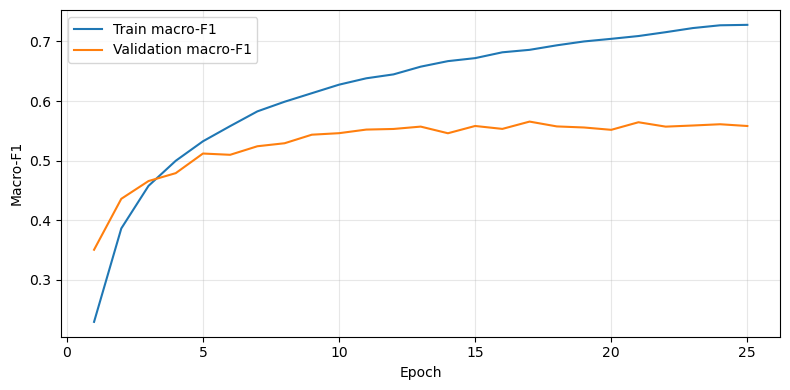

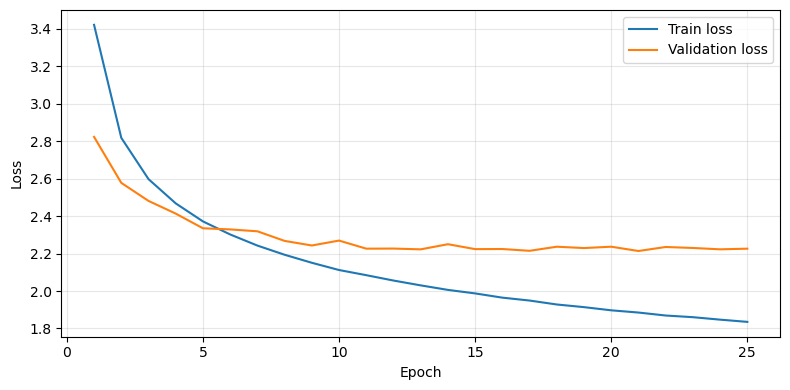

In [6]:
hist = pd.read_csv(HISTORY_PATH)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["epoch"], hist["train_macro_f1"], label="Train macro-F1")
ax.plot(hist["epoch"], hist["val_macro_f1"], label="Validation macro-F1")
ax.set_xlabel("Epoch"); ax.set_ylabel("Macro-F1")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["epoch"], hist["train_loss"], label="Train loss")
ax.plot(hist["epoch"], hist["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## 6. Evaluate the best checkpoint on the held-out test set

Evaluate the test set once after model selection. Use validation metrics for choosing settings.


In [7]:
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)
best_model = PoseLSTM(
    checkpoint["input_size"], checkpoint["hidden_size"],
    checkpoint["num_layers"], checkpoint["num_classes"],
    checkpoint["dropout"]
).to(DEVICE)
best_model.load_state_dict(checkpoint["model_state"])
best_model.eval()

test_loader = DataLoader(
    PoseSequenceDataset(X_test, y_test), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
truths, predictions = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        logits = best_model(xb)
        predictions.append(logits.argmax(dim=1).cpu().numpy())
        truths.append(yb.numpy())

y_true, y_pred = np.concatenate(truths), np.concatenate(predictions)
metrics = {
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_validation_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "test_macro_f1": float(f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                    average="macro", zero_division=0)),
    "test_samples": int(len(y_true)),
}
metrics_path = OUTPUT_REPORT_DIR / "lstm_bilstm_attention_regularized_test_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))
print("Saved metrics:", metrics_path)


{
  "best_epoch": 17,
  "best_validation_macro_f1": 0.5654801521004088,
  "test_accuracy": 0.6283021562187634,
  "test_balanced_accuracy": 0.5504147878922219,
  "test_macro_f1": 0.5478226004632688,
  "test_samples": 21009
}
Saved metrics: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_bilstm_attention_regularized_test_metrics.json
